In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.mixture import GaussianMixture

# Two-dimensional data with bottleneck

## Create two-moons dataset

In [26]:
# Noise level 0.1
X_train_01, _ = make_moons(n_samples=2000, noise=0.1, random_state=42)
X_test_01, _ = make_moons(n_samples=500, noise=0.1, random_state=42)

# Noise level 0.2
X_train_02, _ = make_moons(n_samples=2000, noise=0.2, random_state=42)
X_test_02, _ = make_moons(n_samples=500, noise=0.2, random_state=42)

## Build the autoencoder

In [3]:
class Autoencoder(nn.Module):
    def __init__(self, input_size=2, bottleneck_size=1, hidden_size=16, layers=2):
        super(Autoencoder, self).__init__()
        
        # Encoder: Linear + ReLU for interior, Linear for output
        encoder_modules = []
        current_dim = input_size
        for _ in range(layers):
            encoder_modules.append(nn.Linear(current_dim, hidden_size))
            encoder_modules.append(nn.ReLU())
            current_dim = hidden_size
        encoder_modules.append(nn.Linear(hidden_size, bottleneck_size))
        self.encoder = nn.Sequential(*encoder_modules)
        
        # Decoder: Mirror of encoder
        decoder_modules = []
        current_dim = bottleneck_size
        for _ in range(layers):
            decoder_modules.append(nn.Linear(current_dim, hidden_size))
            decoder_modules.append(nn.ReLU())
            current_dim = hidden_size
        decoder_modules.append(nn.Linear(hidden_size, input_size))
        self.decoder = nn.Sequential(*decoder_modules)

    def forward(self, x):
        return self.decoder(self.encoder(x))
    
    def encode(self, x):
        return self.encoder(x)
    
    def decode(self, code):
        return self.decoder(code)

## Train the autoencoder

In [ ]:
def train_autoencoder(model, data, batch_size=32, epochs=50, lr=0.001):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    
    tensor_data = torch.FloatTensor(data)
    dataset = torch.utils.data.TensorDataset(tensor_data)
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    epoch_losses = []
    for epoch in range(epochs):
        batch_losses = []
        for batch in dataloader:
            x_batch = batch[0]
            
            optimizer.zero_grad()
            reconstructed = model(x_batch)
            loss = criterion(reconstructed, x_batch)
            loss.backward()
            optimizer.step()
            
            batch_losses.append(loss.item())
            
        epoch_losses.append(np.mean(batch_losses))
        
    return epoch_losses

## Investigate hyperparameters

In [11]:
# Helper function to prevent repeatition
def evaluate_model(hidden_size, layers, train_data, test_data, batch_size=32, epochs=20, lr=0.001):
    model = Autoencoder(hidden_size=hidden_size, layers=layers)
    train_autoencoder(model, train_data, batch_size=batch_size, epochs=epochs, lr=lr)
    
    with torch.no_grad():
        recon = model(torch.FloatTensor(test_data))
        test_loss = nn.MSELoss()(recon, torch.FloatTensor(test_data)).item()
        
    return recon.numpy(), test_loss

### Architecture hyperparameter study

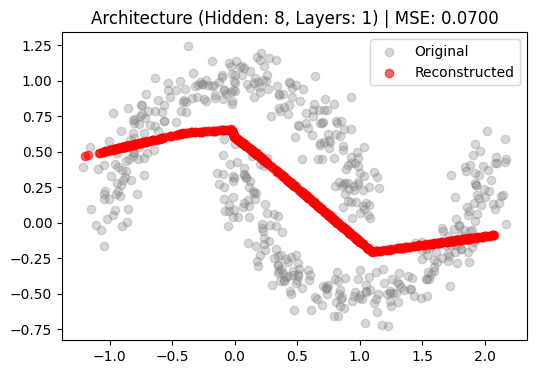

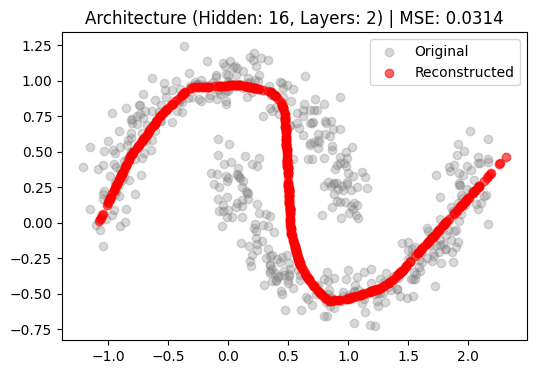

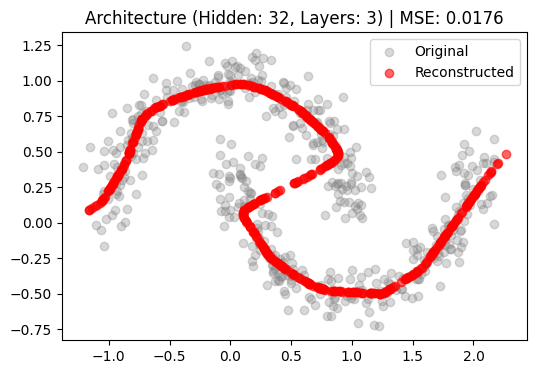

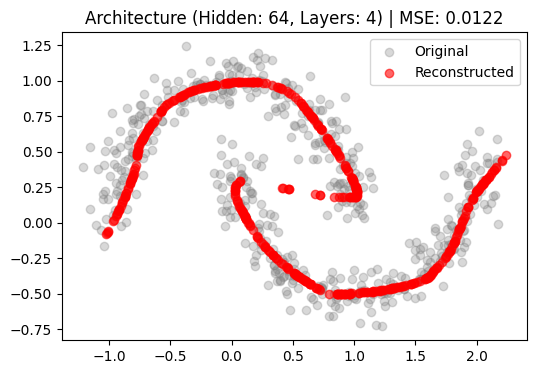

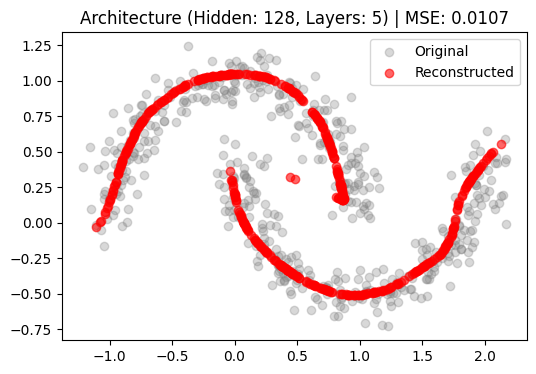

Best Architecture Found -> Hidden Size: 64, Layers: 5, MSE: 0.006095169112086296


In [ ]:
# Running Architecture Study (Fixed Training Rules)
arch_results = {}
subset_to_plot = [(8, 1), (16, 2), (32, 3), (64, 4), (128, 5)]

for hs in [8, 16, 32, 64, 128]:
    for l in [1, 2, 3, 4, 5]:
        recon_np, test_loss = evaluate_model(hs, l, X_train_01, X_test_01)
        arch_results[(hs, l)] = test_loss
        
        # Plot only if the current combination is in the targeted subset
        if (hs, l) in subset_to_plot:
            plt.figure(figsize=(6, 4))
            plt.scatter(X_test_01[:, 0], X_test_01[:, 1], alpha=0.3, color="gray", label="Original")
            plt.scatter(recon_np[:, 0], recon_np[:, 1], alpha=0.6, color="red", label="Reconstructed")
            plt.title(f"Architecture (Hidden: {hs}, Layers: {l}) | MSE: {test_loss:.4f}")
            plt.legend()
            plt.show()

# Extract best architecture settings dynamically
best_hs, best_l = min(arch_results, key=arch_results.get)
lowest_mse = min(arch_results.values())
print(f"Best Architecture Found -> Hidden Size: {best_hs}, Layers: {best_l}, MSE: {lowest_mse:4f}")

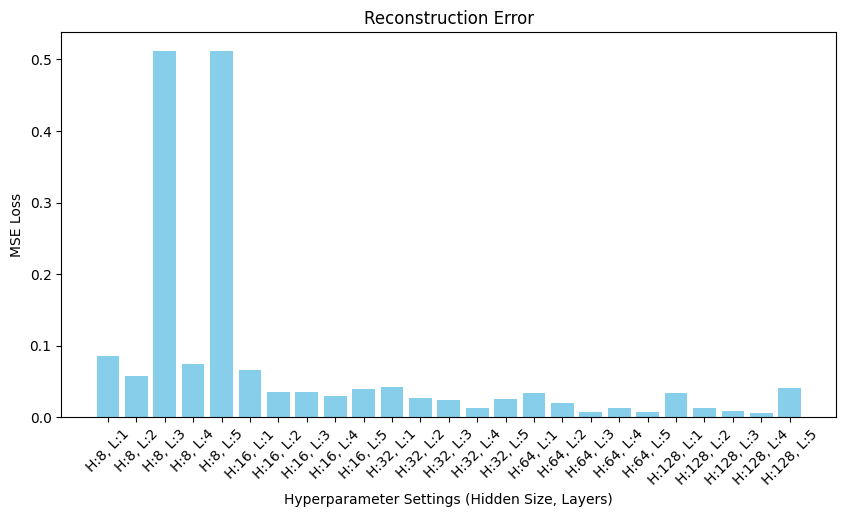

In [19]:
# Create labels for the x-axis by combining hidden_size and layers
hp_labels = [f"H:{hs}, L:{l}" for (hs, l) in arch_results.keys()]
# Extract the corresponding reconstruction errors (MSE)
errors = list(arch_results.values())

plt.figure(figsize=(10, 5))
plt.bar(hp_labels, errors, color='skyblue')
plt.xlabel("Hyperparameter Settings (Hidden Size, Layers)")
plt.ylabel("MSE Loss")
plt.title("Reconstruction Error")
plt.xticks(rotation=45)
plt.show()

The architeture hyperparameter investigation identified hidden_size=128 and layers=4 as the best configuration because it achieved the lowest test MSE and produced the best reconstruction quality among the tested configurations.

### Training hyperparameter study

In [14]:
# Running Training Study (Using Best Architecture)

# Sub-Experiment 1: Learning Rate vs Batch Size (Fixed Epochs=30)
batch_sizes = [16, 32, 128]
learning_rates = [0.01, 0.001, 0.0001]
lr_bs_results = {}

for bs in batch_sizes:
    for lr in learning_rates:
        _, test_loss = evaluate_model(best_hs, best_l, X_train_01, X_test_01, batch_size=bs, epochs=30, lr=lr)
        lr_bs_results[(bs, lr)] = test_loss

# Sub-Experiment 2: Training Set Size vs Epochs (Fixed Batch=32, LR=0.001)
training_sizes = [200, 1000, 3000]
epochs_list = [10, 50, 100]
ts_ep_results = {}

for ts in training_sizes:
    # Generate custom-sized training sets on the fly
    X_train_custom, _ = make_moons(n_samples=ts, noise=0.1, random_state=42)
    for ep in epochs_list:
        _, test_loss = evaluate_model(best_hs, best_l, X_train_custom, X_test_01, epochs=ep)
        ts_ep_results[(ts, ep)] = test_loss

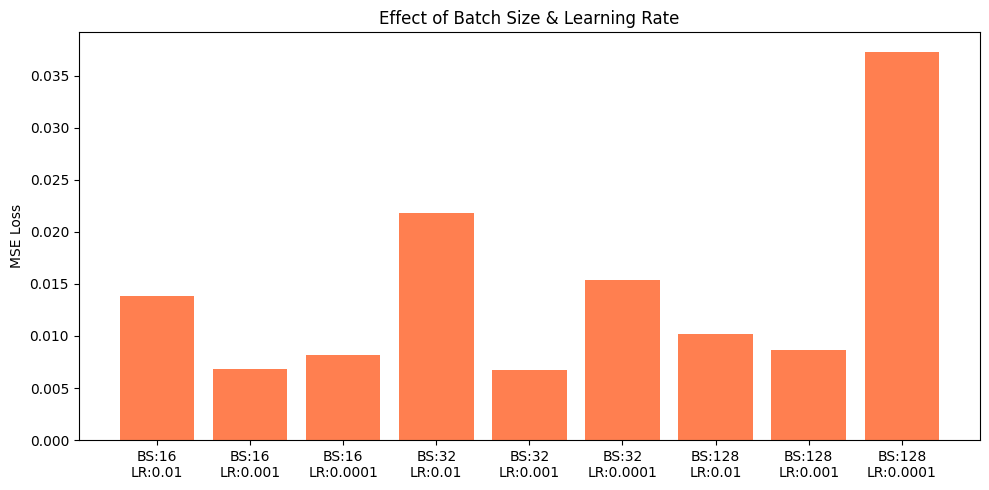

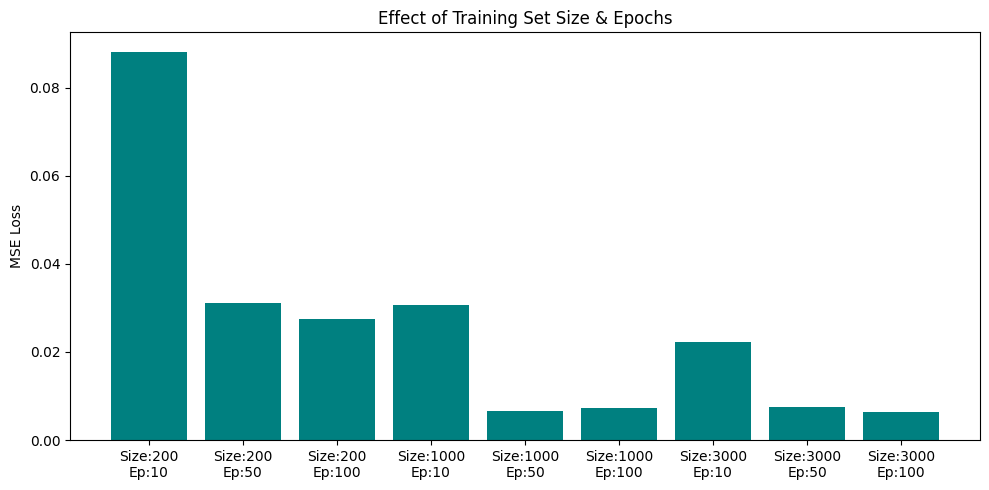

In [16]:
# Batch size and learning rate
labels_a = [f"BS:{bs}\nLR:{lr}" for bs, lr in lr_bs_results.keys()]

plt.figure(figsize=(10, 5))
plt.bar(labels_a, list(lr_bs_results.values()), color="coral")
plt.title("Effect of Batch Size & Learning Rate")
plt.ylabel("MSE Loss")
plt.tight_layout()
plt.show()


# Training set size and epochs
labels_b = [f"Size:{ts}\nEp:{ep}" for ts, ep in ts_ep_results.keys()]

plt.figure(figsize=(10, 5))
plt.bar(labels_b, list(ts_ep_results.values()), color="teal")
plt.title("Effect of Training Set Size & Epochs")
plt.ylabel("MSE Loss")
plt.tight_layout()
plt.show()

For Mini-Batch Size & Learning Rate: A balanced learning rate paired with a small-to-medium batch size consistently gives the lowest MSE loss. If the learning rate is too high, the model takes giant steps and keeps bouncing past the optimal solution, which hurts reconstruction quality. On the flip side, pairing a large batch size with a tiny learning rate means the model takes tiny steps and updates its weights very few times per epoch, leaving it undertrained when time runs out.

For Training Set Size & Number of Epochs: If the training set is too small, the dots are too sparse to outline the full curve of the moons—so even if you train for lots of epochs, the MSE loss stays high because the model is missing parts of the shape. Once you use a large enough dataset to clearly show the moons, training for more epochs quickly drops the MSE loss until the model gets the shape right, after which extra data or extra epochs barely help.

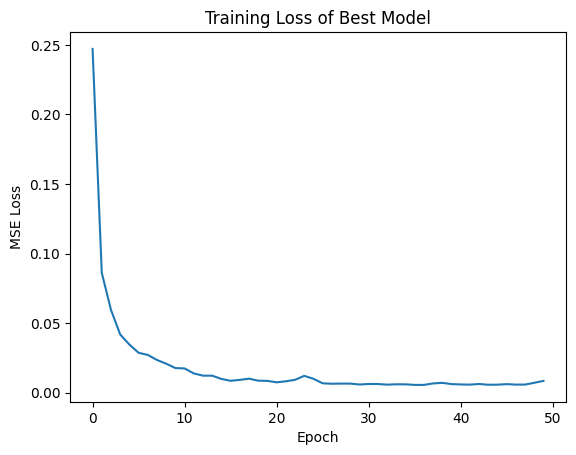

In [21]:
# Training Final Optimal Model for subsequent steps
best_model = Autoencoder(hidden_size=best_hs, layers=best_l)
best_model_losses = train_autoencoder(best_model, X_train_01, batch_size=32, epochs=50, lr=0.001)

plt.plot(best_model_losses)
plt.title("Training Loss of Best Model")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.show()

## Repeat training experiments for the best hyperparameter settings

     Trial 1 Loss: 0.0063
     Trial 2 Loss: 0.0063
     Trial 3 Loss: 0.0062
     Trial 4 Loss: 0.0089
     Trial 5 Loss: 0.0058
     Trial 1 Loss: 0.0072
     Trial 2 Loss: 0.0068
     Trial 3 Loss: 0.0072
     Trial 4 Loss: 0.0117
     Trial 5 Loss: 0.0072


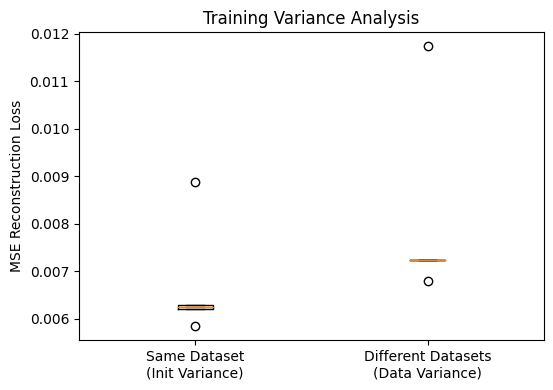

   Same Data Variance: 0.000001
   Diff Data Variance: 0.000003


In [22]:
num_trials = 5
variance_same_data = []
variance_diff_data = []

# Train multiple models on the exact same dataset to see initialization variance
for trial in range(num_trials):
    model = Autoencoder(hidden_size=best_hs, layers=best_l)
    # Using the original X_train_01 and X_test_01
    train_autoencoder(model, X_train_01, epochs=50)
    
    with torch.no_grad():
        recon = model(torch.FloatTensor(X_test_01))
        test_loss = nn.MSELoss()(recon, torch.FloatTensor(X_test_01)).item()
        
    variance_same_data.append(test_loss)
    print(f"     Trial {trial+1} Loss: {test_loss:.4f}")

# Train multiple models on newly generated datasets to see data variance
for trial in range(num_trials):
    # Generate a brand new dataset for this specific trial
    new_X_train, _ = make_moons(n_samples=2000, noise=0.1)
    new_X_test, _ = make_moons(n_samples=500, noise=0.1)
    
    model = Autoencoder(hidden_size=best_hs, layers=best_l)
    train_autoencoder(model, new_X_train, epochs=50)
    
    with torch.no_grad():
        recon = model(torch.FloatTensor(new_X_test))
        test_loss = nn.MSELoss()(recon, torch.FloatTensor(new_X_test)).item()
        
    variance_diff_data.append(test_loss)
    print(f"     Trial {trial+1} Loss: {test_loss:.4f}")

# Visualize the variance
plt.figure(figsize=(6, 4))
plt.boxplot([variance_same_data, variance_diff_data], labels=['Same Dataset\n(Init Variance)', 'Different Datasets\n(Data Variance)'])
plt.ylabel('MSE Reconstruction Loss')
plt.title('Training Variance Analysis')
plt.show()

print(f"   Same Data Variance: {np.var(variance_same_data):.6f}")
print(f"   Diff Data Variance: {np.var(variance_diff_data):.6f}")

Both experiments show very low variance which confirm that our chosen hyperparameters produce a stable model. When we repeat training on the same dataset, it consistently yields the same low MSE loss (aside from one minor random-initialization outlier), while training on new datasets shows slightly higher error and spread as the model adapts to different random noise.

## Analyze the latent code and Fit a GMM and generate samples

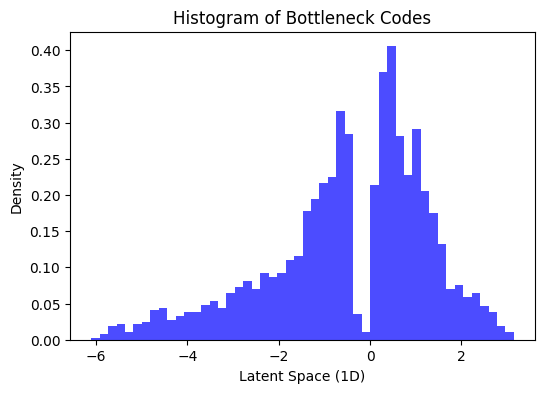

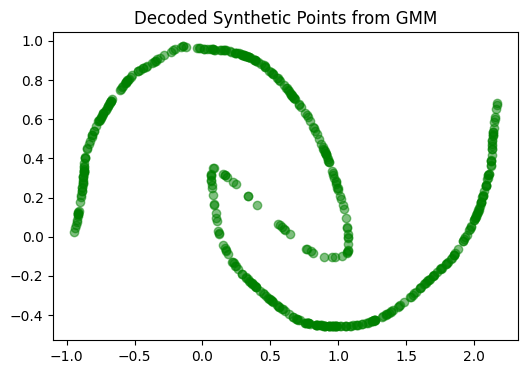

In [24]:
with torch.no_grad():
    latent_codes = best_model.encode(torch.FloatTensor(X_train_01)).numpy()
    
plt.figure(figsize=(6, 4))
plt.hist(latent_codes, bins=50, density=True, alpha=0.7, color='blue')
plt.title("Histogram of Bottleneck Codes")
plt.xlabel("Latent Space (1D)")
plt.ylabel("Density")
plt.show()

# Fit the 1D GMM to the latent codes
gmm = GaussianMixture(n_components=5, random_state=42)
gmm.fit(latent_codes)

# Sample new synthetic latent codes
synthetic_codes, _ = gmm.sample(500)

with torch.no_grad():
    # Decode them back to 2D
    synthetic_2d = best_model.decode(torch.FloatTensor(synthetic_codes)).numpy()
    
plt.figure(figsize=(6, 4))
plt.scatter(synthetic_2d[:, 0], synthetic_2d[:, 1], alpha=0.5, color='green')
plt.title("Decoded Synthetic Points from GMM")
plt.show()

The generated points capture the curved two-moons geometry well, but form thin, noiseless 1D curves instead of replicating the original 2D noise. Additionally, because the GMM slightly smooths over the narrow gap near zero in the 1D latent space, a few stray "bridge" points appear connecting the two moons.

## Test on noise 0.2 without retraining

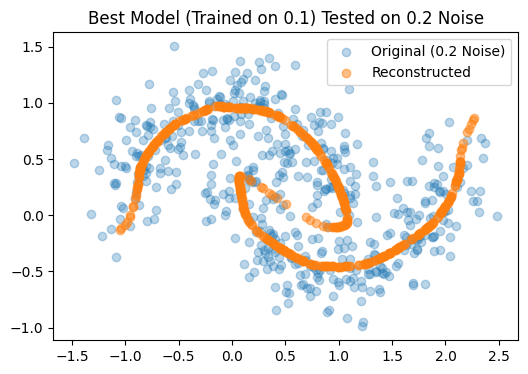

In [27]:
with torch.no_grad():
    recon_02_original_model = best_model(torch.FloatTensor(X_test_02)).numpy()

plt.figure(figsize=(6, 4))
plt.scatter(X_test_02[:, 0], X_test_02[:, 1], alpha=0.3, label="Original (0.2 Noise)")
plt.scatter(recon_02_original_model[:, 0], recon_02_original_model[:, 1], alpha=0.5, label="Reconstructed")
plt.title("Best Model (Trained on 0.1) Tested on 0.2 Noise")
plt.legend()
plt.show()

## Retrain on noise 0.2

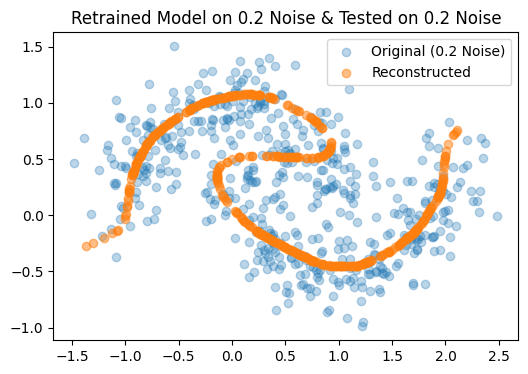

In [ ]:
model_02 = Autoencoder(hidden_size=best_hs, layers=best_l)
train_autoencoder(model_02, X_train_02, epochs=50)

with torch.no_grad():
    recon_02_retrained = model_02(torch.FloatTensor(X_test_02)).numpy()
    
plt.figure(figsize=(6, 4))
plt.scatter(X_test_02[:, 0], X_test_02[:, 1], alpha=0.3, label="Original (0.2 Noise)")
plt.scatter(recon_02_retrained[:, 0], recon_02_retrained[:, 1], alpha=0.5, label="Reconstructed")
plt.title("Retrained Model (Trained on 0.2) Tested on 0.2 Noise")
plt.legend()
plt.show()

When the retrained model (trained on 0.2) tested on the high-noise (0.2) test set, it maps a wider, more relaxed geometry that adequately covers the scattered test points. In contrast, the original model (trained on 0.1) retains the tighter, sharper curves it originally learned, failing to cover the outer boundaries and scattered noise of the new 0.2 test data.

# Two-dimensional data without bottleneck

## Define MMD Loss and the New Training Loop

In [30]:
def compute_mmd(z, z_true, bandwidths):
    """Computes Maximum Mean Discrepancy using a sum of Squared Exponentials."""
    # Calculate pairwise squared Euclidean distances
    xx = torch.cdist(z, z, p=2)**2
    yy = torch.cdist(z_true, z_true, p=2)**2
    xy = torch.cdist(z, z_true, p=2)**2
    
    mmd_loss = 0
    for h in bandwidths:
        # Squared Exponential kernel[cite: 18]
        k_xx = torch.exp(-xx / (h**2))
        k_yy = torch.exp(-yy / (h**2))
        k_xy = torch.exp(-xy / (h**2))
        
        mmd_loss += k_xx.mean() + k_yy.mean() - 2 * k_xy.mean()
        
    return mmd_loss

def train_mmd_autoencoder(model, data, batch_size=32, epochs=150, lr=0.001, mmd_weight=1.0):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    
    # 3 to 7 bandwidths, each value twice the next smaller one
    bandwidths = [0.2, 0.4, 0.8, 1.6, 3.2] 
    
    tensor_data = torch.FloatTensor(data)
    dataset = torch.utils.data.TensorDataset(tensor_data)
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    epoch_losses = []
    for epoch in range(epochs):
        batch_losses = []
        for batch in dataloader:
            x_batch = batch[0]
            
            optimizer.zero_grad()
            
            # Forward pass
            code = model.encode(x_batch)
            reconstructed = model.decode(code)
            
            # Reconstruction Loss
            loss_rec = criterion(reconstructed, x_batch)
            
            # MMD Loss against 2D Standard Normal
            z_true = torch.randn_like(code) 
            loss_mmd = compute_mmd(code, z_true, bandwidths)
            
            # Total Loss is a weighted sum
            loss = loss_rec + mmd_weight * loss_mmd
            
            loss.backward()
            optimizer.step()
            
            batch_losses.append(loss.item())
            
        epoch_losses.append(np.mean(batch_losses))
        
    return epoch_losses

## Train the 2D Bottleneck Autoencoder

Training MMD Autoencoder for 150 epochs (MMD weight: 0.5)...


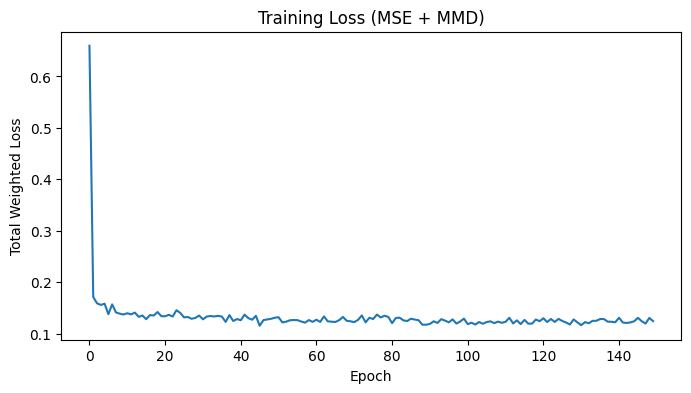

In [31]:
# Initialize Autoencoder with bottleneck_size=2
best_hs = 128
best_l = 4
mmd_model = Autoencoder(input_size=2, bottleneck_size=2, hidden_size=best_hs, layers=best_l)

# MMD weight requires hyperparameter tuning; 0.5 is an effective starting baseline
mmd_weight = 0.5 
print(f"Training MMD Autoencoder for 150 epochs (MMD weight: {mmd_weight})...")

# Convergence takes considerable time (150 epochs)
mmd_losses = train_mmd_autoencoder(mmd_model, X_train_01, batch_size=32, epochs=150, lr=0.001, mmd_weight=mmd_weight)

plt.figure(figsize=(8, 4))
plt.plot(mmd_losses)
plt.title("Training Loss (MSE + MMD)")
plt.xlabel("Epoch")
plt.ylabel("Total Weighted Loss")
plt.show()

## Evaluate Reconstructions & Latent Space

MMD Autoencoder Test: MSE (Bottleneck 2): 0.0026


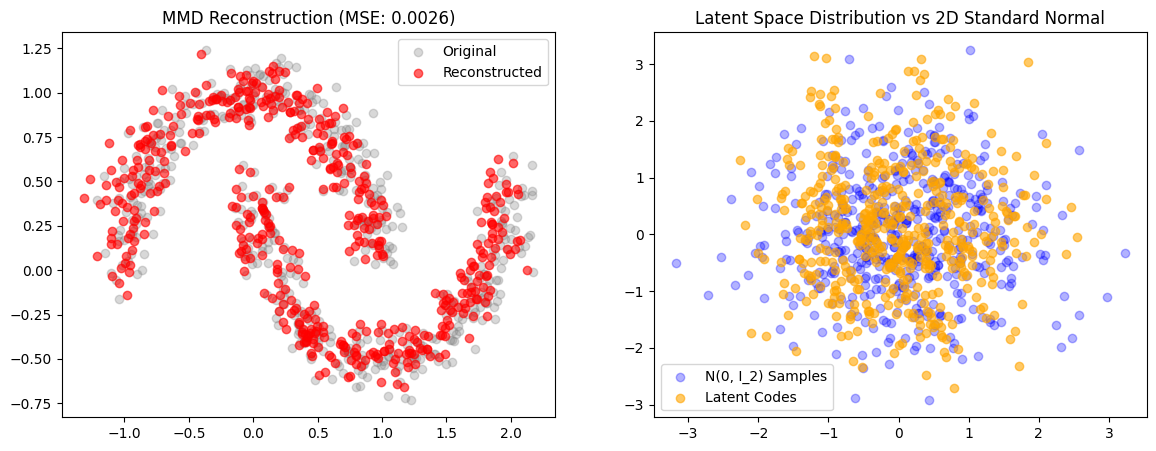

In [36]:
# Reconstruct Test Points
with torch.no_grad():
    recon_mmd = mmd_model(torch.FloatTensor(X_test_01)).numpy()
    test_mse = nn.MSELoss()(torch.FloatTensor(recon_mmd), torch.FloatTensor(X_test_01)).item()
    latent_codes_mmd = mmd_model.encode(torch.FloatTensor(X_test_01)).numpy()
    
print(f"MMD Autoencoder Test: MSE (Bottleneck 2): {test_mse:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Reconstructions
ax1.scatter(X_test_01[:, 0], X_test_01[:, 1], alpha=0.3, color="gray", label="Original")
ax1.scatter(recon_mmd[:, 0], recon_mmd[:, 1], alpha=0.6, color="red", label="Reconstructed")
ax1.set_title(f"MMD Reconstruction (MSE: {test_mse:.4f})")
ax1.legend()

# Latent Distribution vs Standard Normal
z_true_sample = np.random.randn(500, 2)
ax2.scatter(z_true_sample[:, 0], z_true_sample[:, 1], alpha=0.3, color="blue", label="N(0, I_2) Samples")
ax2.scatter(latent_codes_mmd[:, 0], latent_codes_mmd[:, 1], alpha=0.6, color="orange", label="Latent Codes")
ax2.set_title("Latent Space Distribution vs 2D Standard Normal")
ax2.legend()

plt.show()

## Generate Synthetic Data

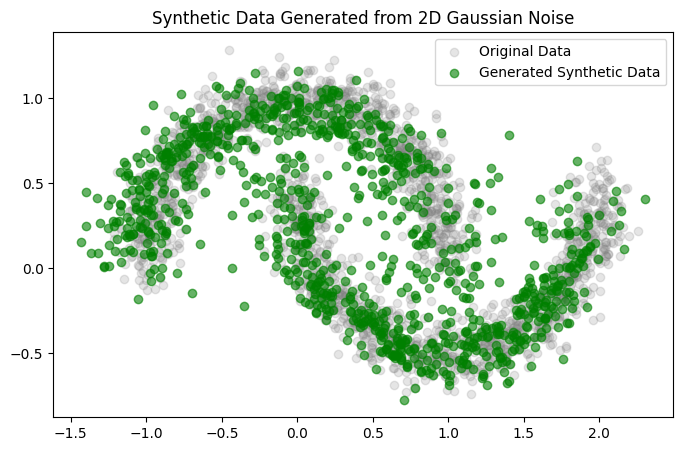

In [33]:
# Generate Synthetic Data by passing standard normal samples through the decoder
n_synthetic = 1000
z_synthetic = torch.randn(n_synthetic, 2)

with torch.no_grad():
    synthetic_2d = mmd_model.decode(z_synthetic).numpy()
    
plt.figure(figsize=(8, 5))
plt.scatter(X_train_01[:, 0], X_train_01[:, 1], alpha=0.2, color="gray", label="Original Data")
plt.scatter(synthetic_2d[:, 0], synthetic_2d[:, 1], alpha=0.6, color="green", label="Generated Synthetic Data")
plt.title("Synthetic Data Generated from 2D Gaussian Noise")
plt.legend()
plt.show()